# Altair multimodal perturbation atlas — cross-modal inspection
**Dataset:** *A multimodal perturbation atlas defines the phenotypic resolution of cellular morphology* (CZ Biohub; Zenodo [20495192](https://zenodo.org/records/20495192)).
1,000 pooled CRISPR knockouts in A549 cells profiled by fluorescence imaging, **label-free quantitative phase imaging**, and **scRNA-seq** (~57M single cells). This Zenodo archive holds the *precomputed gene-level perturbation embeddings* (no raw data).

**The question:** on a clean public benchmark — *do morphology embeddings and transcriptome embeddings encode the same gene-function structure?* Here morphology = quantitative **phase** (label-free), transcriptome = **scRNA-seq**.

**What this notebook does**
1. Catalogues what is in each embedding and which perturbations/modalities are covered.
2. Sanity-check UMAPs of each modality's gene embedding.
3. Tests cross-modal agreement three ways (gene-gene structure correlation, kNN neighbor sharing, CCA).
4. Validates against known biology (CORUM protein complexes).

**Takeaway (computed below):** the two modalities share a large, biologically real chunk of gene-function geometry (ρ≈0.47; ~20× above-chance neighbor sharing; both recover CORUM complexes) **but most of each modality's local neighborhood is modality-specific** — i.e. phase imaging carries gene-function information scRNA-seq does not, and vice versa.

## Data provenance, environment & how to run

**Source:** *A multimodal perturbation atlas defines the phenotypic resolution of cellular morphology* (CZ Biohub, Leonetti lab). Zenodo record **20495192** → `altair.zip` (54 MB, md5 `baf7974ac926445c726760fed57525ab`). **Precomputed gene-level embeddings only — no raw data** (raw imaging + RNA at biohub.ai). Analysis repo: `czbiohub-sf/ops-paper-analysis`.

**Design:** 1,000 pooled CRISPR KOs in A549; fluorescence + label-free quantitative phase imaging + scRNA-seq; ~57M cells.

**Files used**
- `data/cropseq_svaeplus_embedding_phate.h5ad` — scRNA-seq gene embedding (1001 × 50 `X_sVAE`; CORUM/GO/leiden annotations)
- `data/ops_gene_embedding_phate_phase_only.h5ad` — phase-imaging gene embedding (1052 × 97; same annotations)
- `data/cropseq_svaeplus.h5ad` — guide-level scRNA-seq (4206 sgRNA × 50); `data/ops_phase_only.h5ad` — per-perturbation phase (1001 × 97)

**Match:** 1000 shared non-control genes (RNA `obs.index` ↔ imaging `obs.perturbation`), each embedding z-scored before cosine geometry.

**Environment:** `uv` venv, Python 3.11 — `anndata scanpy scikit-learn umap-learn matplotlib jupyter` (kernel `altair`).

**Reproduce**
```bash
mkdir -p data && curl -sL -o data/altair.zip "https://zenodo.org/records/20495192/files/altair.zip?download=1"
cd data && unzip -o altair.zip && cd ..
source .venv/bin/activate
jupyter nbconvert --to notebook --execute --inplace --ExecutePreprocessor.kernel_name=altair altair_inspection.ipynb
```
Figures are also saved to `figures/inspection/`.


In [1]:
import anndata as ad, numpy as np, pandas as pd, warnings
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.cross_decomposition import CCA
from scipy.stats import spearmanr
import umap
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi":110, "font.size":10, "axes.spines.top":False, "axes.spines.right":False})
rng = np.random.default_rng(0)
DATA = "data"; FIG = "figures/inspection"
import os; os.makedirs(FIG, exist_ok=True)

## 1. What is in each embedding?

In [2]:
rna  = ad.read_h5ad(f"{DATA}/cropseq_svaeplus_embedding_phate.h5ad")   # scRNA-seq gene embedding
guide= ad.read_h5ad(f"{DATA}/cropseq_svaeplus.h5ad")                    # scRNA-seq guide-level
img  = ad.read_h5ad(f"{DATA}/ops_gene_embedding_phate_phase_only.h5ad") # phase-imaging gene embedding

summary = pd.DataFrame([
 {"file":"cropseq_svaeplus_embedding_phate", "modality":"scRNA-seq (gene)",
  "n_perturbations":rna.n_obs, "embedding":"X_sVAE", "dim":rna.obsm["X_sVAE"].shape[1],
  "2D":"X_PHATE", "annotations":"CORUM/GO/Reactome/leiden"},
 {"file":"cropseq_svaeplus (guide)", "modality":"scRNA-seq (guide)",
  "n_perturbations":guide.n_obs, "embedding":"emb_guide", "dim":guide.obsm["emb_guide"].shape[1],
  "2D":"-", "annotations":"sgRNA, Perturbation"},
 {"file":"ops_gene_embedding_phate_phase_only", "modality":"phase imaging (gene)",
  "n_perturbations":img.n_obs, "embedding":"X", "dim":img.X.shape[1],
  "2D":"X_umap / X_phate", "annotations":"CORUM/GO/KEGG/Hallmark/leiden"},
])
summary

,file,modality,n_perturbations,embedding,dim,2D,annotations
0,cropseq_svaeplus_embedding_phate,scRNA-seq (gene),1001,X_sVAE,50,X_PHATE,CORUM/GO/Reactome/leiden
1,cropseq_svaeplus (guide),scRNA-seq (guide),4206,emb_guide,50,-,"sgRNA, Perturbation"
2,ops_gene_embedding_phate_phase_only,phase imaging (gene),1052,X,97,X_umap / X_phate,CORUM/GO/KEGG/Hallmark/leiden


### Coverage: perturbations, guides, cells
Below: how many genes/guides, roughly how many guides per gene, and the per-perturbation single-cell depth on the imaging side.

In [3]:
n_genes_rna = rna.obs.index.nunique()
n_guides = guide.obs["sgRNA"].nunique()
n_pert_guide = guide.obs["Perturbation"].nunique()
ncells = pd.to_numeric(img.obs["n_cells"], errors="coerce")
print(f"scRNA-seq: {n_pert_guide} perturbations (incl. control) | {n_guides} guides "
      f"(~{n_guides/max(n_pert_guide-1,1):.1f} guides/gene) | sVAE dim = {rna.obsm['X_sVAE'].shape[1]}")
print(f"phase imaging: {img.n_obs} perturbations | embedding dim = {img.X.shape[1]}")
print(f"imaging cells/perturbation: median={ncells.median():.0f}  min={ncells.min():.0f}  max={ncells.max():.0f}  total={ncells.sum():,.0f}")
print("control label present in scRNA-seq set:", 'control' in set(rna.obs.index.astype(str)))

scRNA-seq: 1001 perturbations (incl. control) | 4206 guides (~4.2 guides/gene) | sVAE dim = 50
phase imaging: 1052 perturbations | embedding dim = 97
imaging cells/perturbation: median=57200  min=10442  max=129974  total=59,741,782
control label present in scRNA-seq set: True


## 2. Match the modalities on shared genes
We keep genes measured in **both** modalities (excluding controls), then z-score each embedding so cosine geometry is comparable.

In [4]:
rna_idx = rna.obs.index.astype(str)
img_idx = img.obs["perturbation"].astype(str).values
CTRL = {"control","nontargeting","non-targeting","NTC","safe"}
shared = [g for g in rna_idx if g in set(img_idx) and g not in CTRL]
rp = {g:i for i,g in enumerate(rna_idx)}; ip = {g:i for i,g in enumerate(img_idx)}
R = StandardScaler().fit_transform(rna.obsm["X_sVAE"][[rp[g] for g in shared]])
I = StandardScaler().fit_transform(np.asarray(img.X)[[ip[g] for g in shared]])
print(f"shared non-control genes: {len(shared)} | RNA {R.shape} | phase-IMG {I.shape}")

# annotations aligned to shared gene order (for colouring)
img_obs = img.obs.set_index("perturbation")
def ann(col): return img_obs[col].reindex(shared).astype(str).values if col in img_obs else np.array([""]*len(shared))
supercat = ann("supercategory"); corum = ann("corum_complex")

shared non-control genes: 1000 | RNA (1000, 50) | phase-IMG (1000, 97)


## 3. Sanity-check UMAPs
UMAP recomputed from each modality's gene embedding (same method both sides). If the embeddings are meaningful, genes should organise into coherent functional groups. We colour by the dataset's `supercategory` and highlight the largest CORUM complexes.

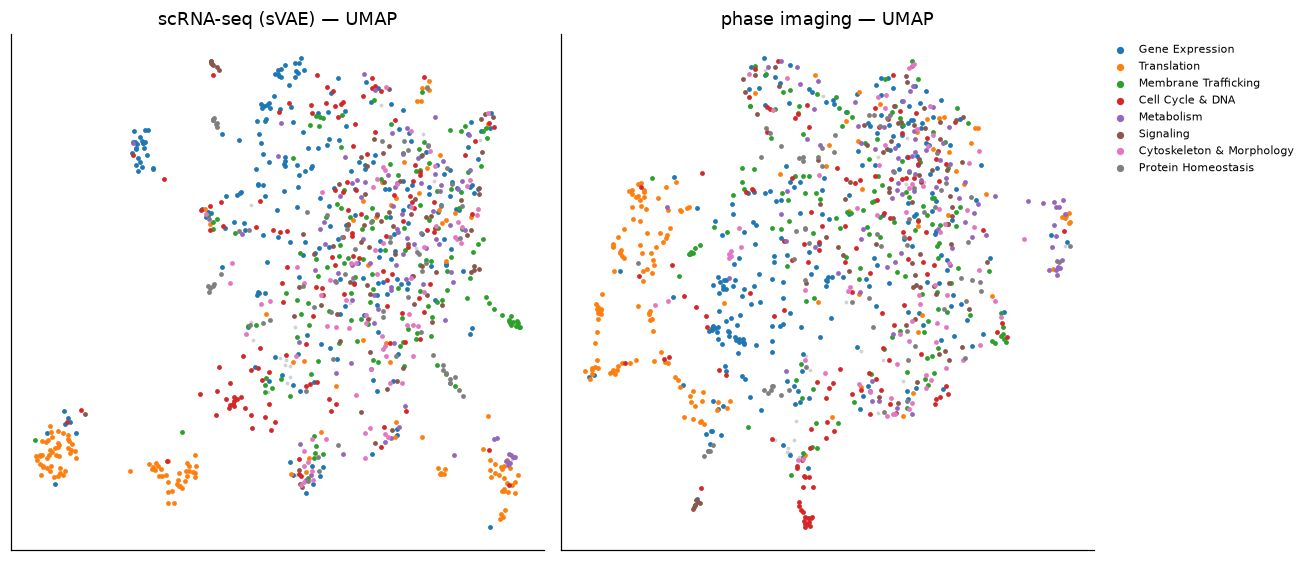

In [5]:
def run_umap(X): return umap.UMAP(n_neighbors=15, min_dist=0.3, metric="cosine", random_state=0).fit_transform(X)
U_rna, U_img = run_umap(R), run_umap(I)

top_cats = [c for c,_ in pd.Series(supercat).value_counts().head(8).items() if c not in ("","nan")]
palette = dict(zip(top_cats, plt.cm.tab10.colors))
def scatter(ax, U, title):
    other = ~np.isin(supercat, top_cats)
    ax.scatter(U[other,0], U[other,1], s=6, c="0.82", linewidths=0)
    for c in top_cats:
        m = supercat==c; ax.scatter(U[m,0],U[m,1], s=10, color=palette[c], label=c, linewidths=0)
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([])
fig,axes = plt.subplots(1,2,figsize=(12,5.2))
scatter(axes[0],U_rna,"scRNA-seq (sVAE) — UMAP")
scatter(axes[1],U_img,"phase imaging — UMAP")
axes[1].legend(fontsize=7, markerscale=1.5, bbox_to_anchor=(1.01,1), loc="upper left", frameon=False)
plt.tight_layout(); plt.savefig(f"{FIG}/umap_both_modalities.png", bbox_inches="tight", dpi=150); plt.show()

## 4. Do the two modalities encode the same gene-gene structure?
**Method (plain language):** within each modality we compute how similar every pair of genes is (cosine similarity of their embeddings). We then ask whether gene pairs that look alike in *morphology* also look alike in *transcriptome* — by correlating the two similarity matrices (Spearman ρ over all gene pairs). A label-shuffled null gives the chance baseline. ρ near 0 = unrelated; ρ near 1 = identical geometry.

Spearman(gene-gene cosine: RNA vs phase) = 0.466  |  null -0.000±0.005  |  z = 103


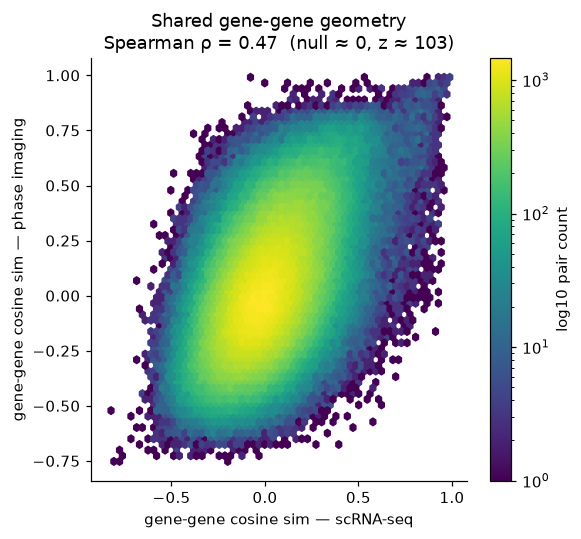

In [6]:
Sr, Si = cosine_similarity(R), cosine_similarity(I)
iu = np.triu_indices(len(shared), k=1); vr, vi = Sr[iu], Si[iu]
rho = spearmanr(vr, vi).statistic
nperm=500; null=np.empty(nperm)
for p in range(nperm):
    perm = rng.permutation(len(shared)); null[p] = spearmanr(vr, Si[np.ix_(perm,perm)][iu]).statistic
z = (rho-null.mean())/null.std()
print(f"Spearman(gene-gene cosine: RNA vs phase) = {rho:.3f}  |  null {null.mean():+.3f}±{null.std():.3f}  |  z = {z:.0f}")

fig,ax = plt.subplots(figsize=(5.4,5))
hb = ax.hexbin(vr, vi, gridsize=60, bins="log", cmap="viridis", mincnt=1)
ax.set_xlabel("gene-gene cosine sim — scRNA-seq"); ax.set_ylabel("gene-gene cosine sim — phase imaging")
ax.set_title(f"Shared gene-gene geometry\nSpearman ρ = {rho:.2f}  (null ≈ 0, z ≈ {z:.0f})")
fig.colorbar(hb, label="log10 pair count"); plt.tight_layout()
plt.savefig(f"{FIG}/structure_hexbin.png", bbox_inches="tight", dpi=150); plt.show()

### 4b. Neighbor sharing (kNN overlap)
**Method:** for each gene, take its *k* nearest neighbors in each modality and measure the fraction shared. This is a stricter, local view than the global correlation. Compared against a shuffled null.

 k  overlap     null  fold_vs_null
 5  0.20640 0.005001     41.268995
10  0.21470 0.010023     21.420020
20  0.22420 0.019884     11.275586
50  0.25044 0.050125      4.996263


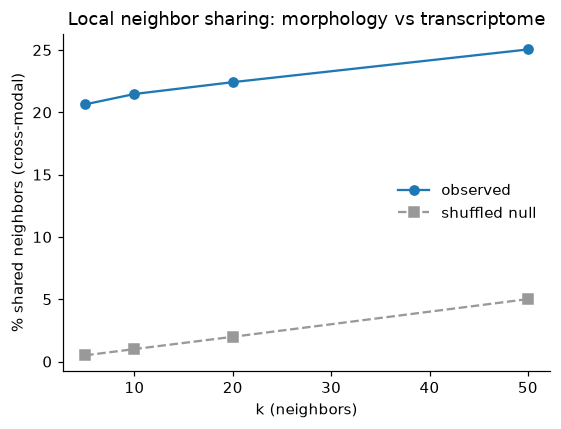

In [7]:
def knn_sets(S,k): 
    idx=np.argsort(-S,axis=1)[:,1:k+1]; return [set(r) for r in idx]
rows=[]
for k in (5,10,20,50):
    nr,ni = knn_sets(Sr,k), knn_sets(Si,k)
    ov = np.mean([len(nr[i]&ni[i])/k for i in range(len(shared))])
    nl=[]
    for p in range(150):
        perm=rng.permutation(len(shared)); inv={perm[i]:i for i in range(len(shared))}
        nip=[set(inv[x] for x in ni[perm[i]]) for i in range(len(shared))]
        nl.append(np.mean([len(nr[i]&nip[i])/k for i in range(len(shared))]))
    nl=np.array(nl); rows.append((k,ov,nl.mean(),ov/nl.mean()))
knn=pd.DataFrame(rows,columns=["k","overlap","null","fold_vs_null"]); print(knn.to_string(index=False))

fig,ax=plt.subplots(figsize=(5.2,4))
ax.plot(knn.k, knn.overlap*100,"o-",label="observed")
ax.plot(knn.k, knn.null*100,"s--",color="0.6",label="shuffled null")
ax.set_xlabel("k (neighbors)"); ax.set_ylabel("% shared neighbors (cross-modal)")
ax.set_title("Local neighbor sharing: morphology vs transcriptome"); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(f"{FIG}/knn_overlap.png", bbox_inches="tight", dpi=150); plt.show()

### 4c. CCA — how many shared axes?
Canonical Correlation Analysis finds matched linear directions across the two embeddings. High canonical correlations = strong shared axes.
**Caveat:** with n=1000 genes and 50/97 dims, in-sample CCA inflates; treat these as an upper bound (a held-out/cross-validated CCA is the rigorous follow-up).

top canonical correlations: [0.977 0.955 0.951 0.932 0.898 0.887 0.874 0.86  0.841 0.829]


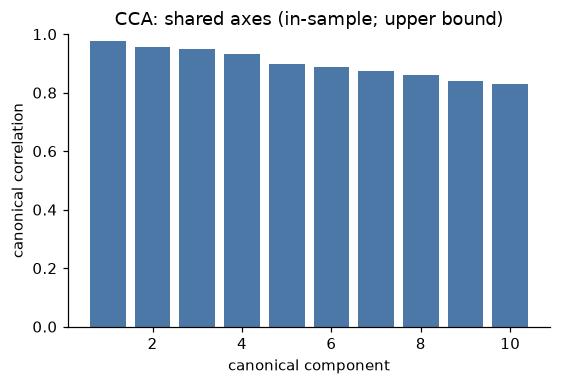

In [8]:
nc=10; cca=CCA(n_components=nc, max_iter=2000); Rc,Ic=cca.fit_transform(R,I)
ccorr=np.array([np.corrcoef(Rc[:,i],Ic[:,i])[0,1] for i in range(nc)])
print("top canonical correlations:", np.round(ccorr,3))
fig,ax=plt.subplots(figsize=(5.2,3.6))
ax.bar(range(1,nc+1), ccorr, color="#4C78A8"); ax.set_ylim(0,1)
ax.set_xlabel("canonical component"); ax.set_ylabel("canonical correlation")
ax.set_title("CCA: shared axes (in-sample; upper bound)")
plt.tight_layout(); plt.savefig(f"{FIG}/cca.png", bbox_inches="tight", dpi=150); plt.show()

## 5. Biological validation — CORUM protein complexes
If the shared structure is real, genes in the **same protein complex** should be close in *both* modalities. We compare same-complex vs other-pair cosine similarity in each modality.

genes in a CORUM complex: 436 | same-complex gene pairs: 466
RNA: same-complex=0.474  other=0.020
phase: same-complex=0.464  other=0.045


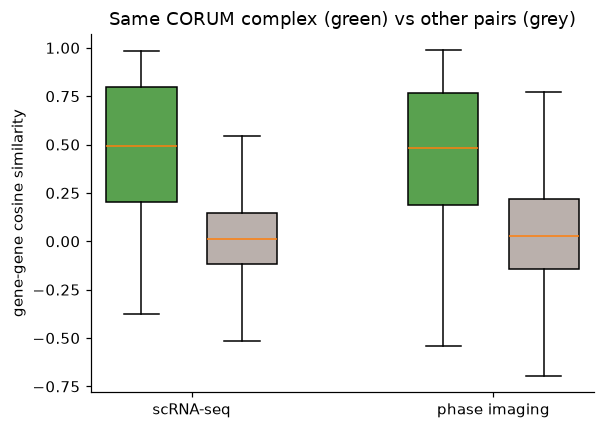

In [9]:
has = (corum!="") & (corum!="nan")
same=np.zeros_like(Sr,dtype=bool)
for c in pd.unique(corum[has]):
    m=np.where(corum==c)[0]
    for a in m:
        for b in m:
            if a<b: same[a,b]=True
sm=same[iu]; print(f"genes in a CORUM complex: {has.sum()} | same-complex gene pairs: {sm.sum()}")
fig,ax=plt.subplots(figsize=(5.6,4))
data=[Sr[iu][sm],Sr[iu][~sm],Si[iu][sm],Si[iu][~sm]]
bp=ax.boxplot(data, positions=[1,2,4,5], widths=0.7, showfliers=False, patch_artist=True)
for patch,c in zip(bp["boxes"], ["#59A14F","#BAB0AC","#59A14F","#BAB0AC"]): patch.set_facecolor(c)
ax.set_xticks([1.5,4.5]); ax.set_xticklabels(["scRNA-seq","phase imaging"])
ax.set_ylabel("gene-gene cosine similarity")
ax.set_title("Same CORUM complex (green) vs other pairs (grey)")
for name,S in [("RNA",Sr),("phase",Si)]:
    print(f"{name}: same-complex={S[iu][sm].mean():.3f}  other={S[iu][~sm].mean():.3f}")
plt.tight_layout(); plt.savefig(f"{FIG}/corum_validation.png", bbox_inches="tight", dpi=150); plt.show()

## 6. Takeaways & next steps

**What we found (shared genes = 1000, A549 CRISPR KO):**
- **Substantial shared geometry** — gene-gene similarity correlates ρ≈0.47 across phase-imaging morphology and scRNA-seq (z≈100 vs shuffled null).
- **Real local agreement** — ~20% of a gene's nearest neighbours are shared across modalities, ~20× above chance; CCA finds many high-correlation shared axes (in-sample upper bound).
- **Biologically grounded** — in both modalities, genes in the same CORUM complex are far more similar than random pairs, so the shared structure reflects true gene function.
- **But mostly non-redundant** — ~80% of each gene's morphological neighbourhood is *not* its transcriptomic neighbourhood. Phase imaging encodes gene-function information scRNA-seq misses (the paper's headline) — the two modalities are complementary, not redundant.

**Extensions:**
1. **Cross-modal prediction** — train morphology→expression (and reverse) on these matched gene embeddings; where it fails marks modality-specific biology (see `cross_modal_prediction.ipynb`).
2. **Which morphology?** — repeat with the *fluorescence* (Cell-Painting-style) embedding vs phase to see which aligns better with transcriptome.
3. **Single cells** — move from gene-level to single-cell cross-modal structure, and test transfer to other cell systems.

**Caveats:** gene-level (pseudobulk) embeddings, not single cells; A549 only (single cell line); CCA numbers are in-sample; phase-only here (fluorescence embedding not in this archive — on biohub.ai).